# CIFAR-10 **Animal** Image Classification with a CNN

This notebook builds a Convolutional Neural Network (CNN) that classifies images into
**6 animal categories** taken from the CIFAR-10 dataset:

> `bird`, `cat`, `deer`, `dog`, `frog`, `horse`

The original CIFAR-10 dataset has 10 classes, 4 of which are vehicles
(`airplane`, `automobile`, `ship`, `truck`). We deliberately **drop the vehicle
classes** so the model only ever has to tell animals apart from other animals.

This notebook is adapted and heavily re-commented from the general structure of
popular public CIFAR-10 CNN walkthroughs (e.g. Farzad Nekouei's
"CIFAR-10 Image Classification with CNN" on Kaggle), rewritten from scratch here so that:

1. Only the **animal** subset of CIFAR-10 is used.
2. Every cell is explained in plain language, aimed at someone who has
   never built a CNN before.
3. At the end, we discuss exactly **which hyperparameters to tune**, and how
   tuning them trades off accuracy against overfitting.

### What is CIFAR-10?
CIFAR-10 is a classic benchmark dataset of 60,000 tiny (32×32 pixel) color
photographs, split into 10 categories, 6,000 images per category
(5,000 for training, 1,000 for testing). It ships directly with Keras, so no
manual download is required — `keras.datasets.cifar10.load_data()` handles it.

### Why filter down to only animals?
- It turns a 10-class problem into an easier **6-class problem**, which is a
  nice way to see how dataset design affects model difficulty.
- Animal classes (bird, cat, deer, dog, frog, horse) are visually more similar
  to *each other* than to vehicles, so this is actually a slightly **harder**
  fine-grained task than the full 10-class problem, even though there are
  fewer classes — a good learning example of "fewer classes doesn't always
  mean easier."


## How to run this notebook

Every result is saved to Google Drive (`OUT_DIR`), so a new session never has to download or retrain anything that already exists. Each cell is labelled with its section and position, e.g. `[SHORTCUT 3/9]`, and stops with a clear message if a cell it depends on hasn't been run yet.

| Section | Run when | Re-run when |
|---|---|---|
| **Setup** (6 cells) | Every new session, top to bottom | You change `FORCE_*` switches, the data split or `LEVELS` |
| **Four-run experiment** (3 cells) | Once; later sessions load the saved runs | You change `LEVELS` or set `FORCE_RETRAIN = True` |
| **Shortcut experiment** (9 cells) | After the four runs; trains the shortcut models once | You change `SC_CFG`; figures (9/9) are optional |
| **Track 1** (7 cells + reload) | Any time after the above; measurement only, takes seconds | You change `T1_CFG`; every run is saved in its own folder |
| **Original walkthrough** (Sections 1–16) | Optional, independent of the experiments | — |

Cells marked *Definitions only* just define functions; re-run them only after editing them.

## Setup
Shared by everything below. Run all six cells at the start of each session.

In [1]:
# [SETUP 1/6] Imports, switches, save location and small helpers.
# Run once per session (re-run only if Colab restarts).
import os, json, time, hashlib
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from scipy.stats import wilcoxon

FORCE_REDOWNLOAD = False   # True = ignore the cached dataset / test sets and rebuild them
FORCE_RETRAIN = False      # True = retrain models even when saved ones exist
SEED = 42
ANIMALS = ['bird', 'cat', 'deer', 'dog', 'frog', 'horse']

# Save to Google Drive if it's connected; otherwise to local Colab disk (lost when the runtime resets).
try:
    from google.colab import drive
    drive.mount('/content/drive', timeout_ms=120000)
except Exception as e:
    print('Drive not connected (', e, ')')
OUT_DIR = ('/content/drive/MyDrive/cifar10_animal_runs' if os.path.isdir('/content/drive/MyDrive')
           else '/content/cifar10_animal_runs')
if not OUT_DIR.startswith('/content/drive'):
    print('WARNING: saving to local Colab disk - copy OUT_DIR to Drive before the session ends.')
DATA_DIR = os.path.join(OUT_DIR, 'data')
os.makedirs(DATA_DIR, exist_ok=True)
print('Saving everything to', OUT_DIR)

def require(*names, cell):
    """Stop with a clear message if an earlier cell hasn't been run in this session."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(f'Missing {missing} - run the "{cell}" cell first.')

def save_model_atomic(model, path):
    """Save to a temp file then rename, so a disconnect mid-save never leaves a corrupt model."""
    tmp = path.replace('.keras', '.partial.keras')
    model.save(tmp); os.replace(tmp, path)

Mounted at /content/drive
Saving everything to /content/drive/MyDrive/cifar10_animal_runs


In [2]:
# [SETUP 2/6] Dataset loader: Hugging Face uoft-cs/cifar10, downloaded once and cached in DATA_DIR.
# Later sessions read the cached file (checked against a checksum) instead of downloading.
HF_DATASET = 'uoft-cs/cifar10'
DATA_FILE = os.path.join(DATA_DIR, 'cifar10_hf_uoft-cs.npz')
META_FILE = os.path.join(DATA_DIR, 'cifar10_hf_uoft-cs.meta.json')

def _sha256(*arrays):
    h = hashlib.sha256()
    for a in arrays:
        h.update(np.ascontiguousarray(a).tobytes())
    return h.hexdigest()

def load_cifar10_cached():
    """((x_train, y_train), (x_test, y_test)): raw uint8 images and (N, 1) labels, as Hugging Face gives them."""
    if os.path.exists(DATA_FILE) and os.path.exists(META_FILE) and not FORCE_REDOWNLOAD:
        with np.load(DATA_FILE) as d:
            arrs = d['x_train'], d['y_train'], d['x_test'], d['y_test']
        with open(META_FILE) as fh:
            meta = json.load(fh)
        if _sha256(*arrs) == meta['sha256']:
            print(f'Loaded cached {HF_DATASET} from {DATA_FILE} (saved {meta["saved_at"]})')
            return (arrs[0], arrs[1]), (arrs[2], arrs[3])
        print('Cached data failed its checksum - downloading again.')
    from datasets import load_dataset
    print(f'Downloading {HF_DATASET} from Hugging Face ...')
    hf = load_dataset(HF_DATASET)
    to_np = lambda split: (np.stack([np.array(im) for im in hf[split]['img']]),
                           np.array(hf[split]['label']).reshape(-1, 1))
    (a, b), (c, d) = to_np('train'), to_np('test')
    tmp = DATA_FILE.replace('.npz', '.partial.npz')        # write-then-rename: no half-written cache
    np.savez(tmp, x_train=a, y_train=b, x_test=c, y_test=d)
    os.replace(tmp, DATA_FILE)
    with open(META_FILE, 'w') as fh:
        json.dump(dict(source=f'https://huggingface.co/datasets/{HF_DATASET}', sha256=_sha256(a, b, c, d),
                       shapes={k: list(v.shape) for k, v in
                               dict(x_train=a, y_train=b, x_test=c, y_test=d).items()},
                       saved_at=time.strftime('%Y-%m-%d %H:%M:%S')), fh, indent=2)
    print('Saved dataset to', DATA_FILE)
    return (a, b), (c, d)

In [3]:
# [SETUP 3/6] Load the data, keep the 6 animal classes, scale to 0-1, split train / validation / test.
# Re-run this cell to get fresh, untouched copies of the arrays.
require('load_cifar10_cached', cell='SETUP 2/6')
(xtr, ytr), (xte, yte) = load_cifar10_cached()

def keep_animals(x, y):
    y = y.flatten(); m = np.isin(y, [2, 3, 4, 5, 6, 7])
    return x[m].astype('float32') / 255.0, (y[m] - 2).astype('int64')

xtr, ytr = keep_animals(xtr, ytr); xte, yte = keep_animals(xte, yte)
perm = np.random.default_rng(SEED).permutation(len(xtr))
xtr, ytr = xtr[perm], ytr[perm]
nval = int(len(xtr) * 0.12)
xval, yval, xtr, ytr = xtr[:nval], ytr[:nval], xtr[nval:], ytr[nval:]
print('train', xtr.shape, 'val', xval.shape, 'test', xte.shape)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Saved dataset to /content/drive/MyDrive/cifar10_animal_runs/data/cifar10_hf_uoft-cs.npz
train (26400, 32, 32, 3) val (3600, 32, 32, 3) test (6000, 32, 32, 3)


In [4]:
# [SETUP 4/6] Augmentation levels and the function that applies them.
# Edit LEVELS here, then re-run this cell and everything below that you want updated.
LEVELS = {
    'run1_original': None,
    'run2_mild':     dict(rotation=0.03, brightness=0.08, contrast=0.10, sat=(0.8, 1.2), hue=0.03, swap_p=0.0),
    'run3_stronger': dict(rotation=0.08, brightness=0.15, contrast=0.25, sat=(0.5, 1.5), hue=0.10, swap_p=0.15),
    'run4_heavy':    dict(rotation=0.12, brightness=0.20, contrast=0.35, sat=(0.3, 1.7), hue=0.25, swap_p=0.60),
}
# rotation factor x 360 = max degrees (0.03 = ±11°, 0.08 = ±29°, 0.12 = ±43°)
# swap_p = chance an image gets its R/G/B channels shuffled (e.g. red fur -> blue fur)

PERMS = tf.constant(np.stack([np.eye(3)[list(p)].T for p in
    [(0,1,2),(0,2,1),(1,0,2),(1,2,0),(2,0,1),(2,1,0)]]), tf.float32)

def make_alter(cfg, seed):
    if cfg is None:
        return lambda x: x
    rot = layers.RandomRotation(cfg['rotation'], fill_mode='reflect', seed=seed)
    def alter(x):
        b = tf.shape(x)[0]
        x = rot(x, training=True)
        x = x + tf.random.uniform([b, 1, 1, 1], -cfg['brightness'], cfg['brightness'])
        mean = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
        x = (x - mean) * tf.random.uniform([b, 1, 1, 1], 1 - cfg['contrast'], 1 + cfg['contrast']) + mean
        hsv = tf.image.rgb_to_hsv(tf.clip_by_value(x, 0., 1.))
        h = tf.math.floormod(hsv[..., 0] + tf.random.uniform([b, 1, 1], -cfg['hue'], cfg['hue']), 1.0)
        s = tf.clip_by_value(hsv[..., 1] * tf.random.uniform([b, 1, 1], cfg['sat'][0], cfg['sat'][1]), 0., 1.)
        x = tf.image.hsv_to_rgb(tf.stack([h, s, hsv[..., 2]], -1))
        if cfg['swap_p'] > 0:
            idx = tf.random.uniform([b], 1, 6, dtype=tf.int32)
            idx = tf.where(tf.random.uniform([b]) < cfg['swap_p'], idx, tf.zeros_like(idx))
            x = tf.einsum('bhwc,bcd->bhwd', x, tf.gather(PERMS, idx))
        return tf.clip_by_value(x, 0., 1.)
    return alter

In [5]:
# [SETUP 5/6] Fixed altered copies of the test set (one per level), cached so every session scores
# exactly the same images. The file name includes a hash of LEVELS, so editing a level makes a new cache.
require('xte', cell='SETUP 3/6'); require('LEVELS', 'make_alter', cell='SETUP 4/6')
lvl_hash = hashlib.sha256(json.dumps(LEVELS, sort_keys=True).encode()).hexdigest()[:10]
TEST_SETS_FILE = os.path.join(DATA_DIR, f'altered_test_sets_seed999_{lvl_hash}.npz')
if os.path.exists(TEST_SETS_FILE) and not FORCE_REDOWNLOAD:
    with np.load(TEST_SETS_FILE) as d:
        test_sets = {k: d[k] for k in LEVELS}
    print('Loaded altered test sets from', TEST_SETS_FILE)
else:
    tf.keras.utils.set_random_seed(999)
    test_sets = {}
    for name, cfg in LEVELS.items():
        f = make_alter(cfg, seed=999)
        test_sets[name] = np.concatenate([f(tf.constant(xte[i:i+500])).numpy() for i in range(0, len(xte), 500)])
    tmp = TEST_SETS_FILE.replace('.npz', '.partial.npz')
    np.savez(tmp, **test_sets); os.replace(tmp, TEST_SETS_FILE)
    print('Saved altered test sets to', TEST_SETS_FILE)

Saved altered test sets to /content/drive/MyDrive/cifar10_animal_runs/data/altered_test_sets_seed999_c913e1460d.npz


In [6]:
# [SETUP 6/6] The CNN used by the four runs and the shortcut experiment.
# (Named build_run_model because Section 7 further down defines a different build_model.)
def build_run_model():
    inp = keras.Input((32, 32, 3)); x = inp
    for f in (32, 64, 128):
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding='same', activation='relu')(x); x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x); x = layers.Dropout(0.25)(x)
    x = layers.Flatten()(x); x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(6, activation='softmax')(x))

def load_run_model(name):
    """Reload a finished augmentation run, e.g. load_run_model('run4_heavy')."""
    return keras.models.load_model(os.path.join(OUT_DIR, name, f'{name}_model.keras'))

## Four-run augmentation experiment
Run 1: no changes | Run 2: mild colour + rotation | Run 3: stronger | Run 4: heavy colour swaps.
Each run trains a CNN on images altered at that level, then tests it on clean test images **and** on test images altered at every level (a robustness check). Saved runs are loaded instead of retrained.

In [ ]:
# [FOUR-RUN 1/3] Train-or-load for one augmentation run. Definitions only; nothing runs yet.
def show_training_samples(ds, name, run_dir):
    sx, sy = next(iter(ds))
    plt.figure(figsize=(10, 3.5))
    for i in range(12):
        plt.subplot(2, 6, i + 1); plt.imshow(sx[i]); plt.title(ANIMALS[int(sy[i])], fontsize=8); plt.axis('off')
    plt.suptitle(f'{name}: training images'); plt.tight_layout()
    plt.savefig(os.path.join(run_dir, 'sample_images.png'), dpi=120); plt.show()

def train_or_load_run(run_i, name, cfg):
    """Returns this run's results dict. Skips training when the model + results are already saved."""
    run_dir = os.path.join(OUT_DIR, name); os.makedirs(run_dir, exist_ok=True)
    model_path = os.path.join(run_dir, f'{name}_model.keras')
    res_path = os.path.join(run_dir, f'{name}_results.json')
    if not FORCE_RETRAIN and os.path.exists(model_path):
        if os.path.exists(res_path):
            print(f'{name}: saved model + results found -> skipping training')
            with open(res_path) as fh:
                return json.load(fh)
        print(f'{name}: saved model found but no results -> loading and re-evaluating')
        model, history, minutes = keras.models.load_model(model_path), {}, None
    else:
        print(f'{name}: training, settings {cfg}')
        tf.keras.utils.set_random_seed(SEED)
        alter = make_alter(cfg, seed=100 + run_i)
        ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=SEED)
              .batch(64).map(lambda x, y: (alter(x), y)).prefetch(tf.data.AUTOTUNE))
        show_training_samples(ds, name, run_dir)
        model = build_run_model()
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        hist = model.fit(ds, validation_data=(xval, yval), epochs=25, verbose=2, callbacks=[
            keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
        history = {k: [float(v) for v in vs] for k, vs in hist.history.items()}
        minutes = round((time.time() - t0) / 60, 1)
        save_model_atomic(model, model_path)
        print('saved model to', model_path)
    acc = {f'test_{k}': float(model.evaluate(v, yte, verbose=0)[1]) for k, v in test_sets.items()}
    res = dict(run=name, settings=cfg, epochs_trained=len(history.get('loss', [])) or None, minutes=minutes,
               best_val_accuracy=float(max(history['val_accuracy'])) if history else None, **acc, history=history)
    with open(res_path, 'w') as fh:
        json.dump(res, fh, indent=2)
    print({k: round(v, 4) for k, v in acc.items()})
    return res

In [ ]:
# [FOUR-RUN 2/3] Run all four levels. Saved runs load in seconds; missing ones train (~3 min each on GPU).
require('test_sets', cell='SETUP 5/6'); require('build_run_model', cell='SETUP 6/6')
require('train_or_load_run', cell='FOUR-RUN 1/3')
run_results = {}
for run_i, (name, cfg) in enumerate(LEVELS.items()):
    run_results[name] = train_or_load_run(run_i, name, cfg)

run1_original: saved model + results found -> skipping training
run2_mild: saved model + results found -> skipping training
run3_stronger: saved model + results found -> skipping training
run4_heavy: saved model + results found -> skipping training


In [ ]:
# [FOUR-RUN 3/3] Comparison table: rows = how the model was trained, columns = which test set.
require('run_results', cell='FOUR-RUN 2/3')
run_table = pd.DataFrame({n: {k.replace('test_', 'tested on '): r[k] for k in r if k.startswith('test_')}
                          for n, r in run_results.items()}).T
run_table.to_csv(os.path.join(OUT_DIR, 'all_runs_summary.csv'))
print('Test accuracy % (rows = trained with, columns = tested on):')
display((run_table * 100).round(2))

Test accuracy % (rows = trained with, columns = tested on):


,tested on run1_original,tested on run2_mild,tested on run3_stronger,tested on run4_heavy
run1_original,84.02,77.87,65.90,50.93
run2_mild,82.35,81.97,70.93,55.57
run3_stronger,81.97,82.52,79.07,72.50
run4_heavy,76.95,76.23,75.28,73.52


## Controlled shortcut experiment (with vs. without the shortcut)
* **Injected shortcut** – a 4×4 colour patch in the corner encodes the class in 95% of training and validation images. Every test image is scored *clean*, with a *neutral grey patch* (occlusion control), with the *correct* patch and with a *wrong-class* patch.
* **Natural colour shortcut** – the same images in grayscale and with RGB→BGR swapped.

Results go to `OUT_DIR/shortcut_experiment/`. Baselines are the four-run models; shortcut models are trained once (cell 3/9) and reloaded afterwards. Cells 4–9 only measure and can be re-run freely.

In [ ]:
# [SHORTCUT 1/9] Settings and the colour patch that acts as the injected shortcut.
# Edit SC_CFG here; re-run this cell and the shortcut cells below it.
require('xtr', 'xval', 'yval', cell='SETUP 3/6')
SC_CFG = dict(
    patch_size=4,                                   # k x k pixels, top-left corner
    shortcut_p=0.95,                                # share of train/val images carrying their class patch
    train_levels=['run1_original', 'run4_heavy'],   # augmentation levels to test (any keys of LEVELS)
    n_per_class=None,                               # None = all test images; e.g. 200 for a quick run
    epochs=25, batch=64, seed=SEED,
)
SC_DIR = os.path.join(OUT_DIR, 'shortcut_experiment'); os.makedirs(SC_DIR, exist_ok=True)
PATCH_SIZE, NC = SC_CFG['patch_size'], len(ANIMALS)
PATCH_COLORS = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1],      # bird=red, cat=green, deer=blue
                         [1, 1, 0], [1, 0, 1], [0, 1, 1]],     # dog=yellow, frog=magenta, horse=cyan
                        'float32')
NEUTRAL = np.array([0.5, 0.5, 0.5], 'float32')

def add_patch(x, colors, mask=None):
    """numpy: paint a KxK patch of the given per-image colour (N,3); mask picks which images."""
    x = x.copy()
    mask = np.ones(len(x), bool) if mask is None else mask
    x[mask, :PATCH_SIZE, :PATCH_SIZE, :] = colors[mask][:, None, None, :]
    return x

def tf_add_patch(x, y, p):
    """tf.data version: each image gets its class patch with probability p, applied AFTER augmentation."""
    if p <= 0:
        return x
    K, (H, W) = PATCH_SIZE, xtr.shape[1:3]
    has = tf.cast(tf.random.uniform([tf.shape(x)[0]]) < p, x.dtype)[:, None, None, None]
    col = tf.gather(tf.constant(PATCH_COLORS), y)[:, None, None, :]
    region = tf.pad(tf.ones([K, K, 1], x.dtype), [[0, H - K], [0, W - K], [0, 0]])[None]
    m = region * has
    return x * (1 - m) + col * m

# Validation follows the training distribution: a clean val set would let EarlyStopping
# quietly select against the shortcut and confound the test.
xval_sc = add_patch(xval, PATCH_COLORS[yval],
                    np.random.default_rng(SC_CFG['seed'] + 1).random(len(xval)) < SC_CFG['shortcut_p'])

In [ ]:
# [SHORTCUT 2/9] Train-or-load for baseline / shortcut models. Definitions only.
def get_sc_model(level, shortcut):
    """Baseline = the model the four-run cells saved. Shortcut = trained here once, then reloaded."""
    tag = 'shortcut' if shortcut else 'baseline'
    out = os.path.join(SC_DIR, f'{level}_{tag}.keras')
    hist_path = out.replace('.keras', '_history.json')
    candidates = [out] if shortcut else [os.path.join(OUT_DIR, level, f'{level}_model.keras'), out]
    for saved in ([] if FORCE_RETRAIN else candidates):
        if os.path.exists(saved):
            print(f'loading {level} | {tag} from {saved} (no retraining)')
            h = json.load(open(hist_path)) if os.path.exists(hist_path) else None
            return keras.models.load_model(saved), h
    print(f'\n=== training {level} | {tag} ===')
    tf.keras.utils.set_random_seed(SC_CFG['seed'])
    alter = make_alter(LEVELS[level], seed=100 + list(LEVELS).index(level))
    p = SC_CFG['shortcut_p'] if shortcut else 0.0
    ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=SC_CFG['seed'])
          .batch(SC_CFG['batch']).map(lambda x, y: (tf_add_patch(alter(x), y, p), y))
          .prefetch(tf.data.AUTOTUNE))
    model = build_run_model()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    hist = model.fit(ds, validation_data=(xval_sc if shortcut else xval, yval),
                     epochs=SC_CFG['epochs'], verbose=2, callbacks=[
        keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
    save_model_atomic(model, out)
    h = {k: [float(v) for v in vs] for k, vs in hist.history.items()}
    with open(hist_path, 'w') as fh:
        json.dump(h, fh)
    print('saved', out)
    return model, h

In [ ]:
# [SHORTCUT 3/9] Load (or, the first time, train) baseline + shortcut models for each level.
require('xval_sc', cell='SHORTCUT 1/9'); require('get_sc_model', cell='SHORTCUT 2/9')
sc_models, sc_histories = {}, {}
for level in SC_CFG['train_levels']:
    for shortcut in (False, True):
        name = f"{level}|{'shortcut' if shortcut else 'baseline'}"
        sc_models[name], sc_histories[name] = get_sc_model(level, shortcut)

loading run1_original | baseline from /content/drive/MyDrive/cifar10_animal_runs/run1_original/run1_original_model.keras (no retraining)
loading run1_original | shortcut from /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment/run1_original_shortcut.keras (no retraining)
loading run4_heavy | baseline from /content/drive/MyDrive/cifar10_animal_runs/run4_heavy/run4_heavy_model.keras (no retraining)
loading run4_heavy | shortcut from /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment/run4_heavy_shortcut.keras (no retraining)


In [ ]:
# [SHORTCUT 4/9] Fixed test images and the six test conditions (same images in every condition).
sc_rng = np.random.default_rng(SC_CFG['seed'] + 2)
if SC_CFG['n_per_class']:
    sc_idx = np.sort(np.concatenate([sc_rng.choice(np.where(yte == c)[0], SC_CFG['n_per_class'], replace=False)
                                     for c in range(NC)]))
else:
    sc_idx = np.arange(len(xte))
sc_x0, sc_y0 = xte[sc_idx], yte[sc_idx]
sc_n = len(sc_idx)
sc_wrong = (sc_y0 + 1) % NC                       # fixed "misleading" class for the conflict test

SC_CONDITIONS = {   # name: (probe family, images)
    'clean':            ('injected_patch', sc_x0),
    'neutral_patch':    ('injected_patch', add_patch(sc_x0, np.tile(NEUTRAL, (sc_n, 1)))),
    'aligned_shortcut': ('injected_patch', add_patch(sc_x0, PATCH_COLORS[sc_y0])),
    'conflicting':      ('injected_patch', add_patch(sc_x0, PATCH_COLORS[sc_wrong])),
    'grayscale':        ('natural_color',  np.repeat(tf.image.rgb_to_grayscale(sc_x0).numpy(), 3, -1)),
    'channel_swap_bgr': ('natural_color',  sc_x0[..., ::-1].copy()),
}
print(f'{sc_n} test images x {len(SC_CONDITIONS)} conditions')

6000 test images x 6 conditions


In [ ]:
# [SHORTCUT 5/9] Per-image predictions + confidence for every model and condition.
require('sc_models', cell='SHORTCUT 3/9'); require('SC_CONDITIONS', cell='SHORTCUT 4/9')
rows, ar = [], np.arange(sc_n)
for mname, model in sc_models.items():
    level, kind = mname.split('|')
    for cname, (family, xc) in SC_CONDITIONS.items():
        prob = model.predict(xc, batch_size=512, verbose=0)
        pred = prob.argmax(1)
        rows.append(pd.DataFrame(dict(
            model=mname, train_level=level, model_kind=kind, probe=family, condition=cname,
            image_idx=sc_idx, true_label=sc_y0, true_name=np.array(ANIMALS)[sc_y0],
            pred_label=pred, pred_name=np.array(ANIMALS)[pred], correct=pred == sc_y0,
            true_conf=prob[ar, sc_y0], max_conf=prob.max(1),
            misleading_class=sc_wrong, misleading_conf=prob[ar, sc_wrong],
            followed_misleading=pred == sc_wrong)))
sc_per_image = pd.concat(rows, ignore_index=True)
sc_per_image.to_csv(os.path.join(SC_DIR, 'per_image_results.csv'), index=False)
print(len(sc_per_image), 'rows saved to per_image_results.csv')

144000 rows saved to per_image_results.csv


In [ ]:
# [SHORTCUT 6/9] Organise: paired with/without table, summary by condition, effect sizes, per class.
require('sc_per_image', cell='SHORTCUT 5/9')
sc_paired = sc_per_image.pivot_table(index=['model', 'image_idx', 'true_name'], columns='condition',
                                     values='true_conf').reset_index()
SC_EFFECTS = {   # name: (with, without, what it isolates)
    'shortcut_gain (aligned - neutral)':     ('aligned_shortcut', 'neutral_patch', 'pure effect of a label-coding colour; occlusion held fixed'),
    'shortcut_harm (conflicting - neutral)': ('conflicting', 'neutral_patch', 'confidence lost when the cue points to a wrong class'),
    'occlusion (neutral - clean)':           ('neutral_patch', 'clean', 'control: cost of covering the corner at all'),
    'color_reliance (clean - grayscale)':    ('clean', 'grayscale', 'confidence that depends on colour'),
    'color_reliance (clean - bgr swap)':     ('clean', 'channel_swap_bgr', 'confidence that depends on the colour mapping'),
}
for ename, (a, b, _) in SC_EFFECTS.items():
    sc_paired[ename] = sc_paired[a] - sc_paired[b]

sc_summary = (sc_per_image.groupby(['model', 'probe', 'condition'], sort=False)
              .agg(n_images=('correct', 'size'), accuracy=('correct', 'mean'),
                   mean_true_conf=('true_conf', 'mean'), median_true_conf=('true_conf', 'median'),
                   mean_max_conf=('max_conf', 'mean'), followed_misleading=('followed_misleading', 'mean'))
              .reset_index())
sc_summary.loc[sc_summary.condition != 'conflicting', 'followed_misleading'] = np.nan

eff_rows = []
for mname, g in sc_paired.groupby('model', sort=False):
    for ename, (a, b, meaning) in SC_EFFECTS.items():
        d = g[ename].to_numpy(); se = d.std(ddof=1) / np.sqrt(len(d))
        try:
            p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
        except ValueError:
            p = np.nan
        eff_rows.append(dict(model=mname, effect=ename, isolates=meaning, mean_delta=d.mean(),
                             ci95_low=d.mean() - 1.96 * se, ci95_high=d.mean() + 1.96 * se,
                             share_images_up=(d > 0.01).mean(), share_images_down=(d < -0.01).mean(),
                             wilcoxon_p=p))
sc_effects = pd.DataFrame(eff_rows)
sc_per_class = (sc_per_image.groupby(['model', 'condition', 'true_name'])
                .agg(accuracy=('correct', 'mean'), mean_true_conf=('true_conf', 'mean')).reset_index())

In [ ]:
# [SHORTCUT 7/9] Save the organised tables and the settings used.
require('sc_effects', cell='SHORTCUT 6/9')
sc_paired.to_csv(os.path.join(SC_DIR, 'paired_confidence.csv'), index=False)
sc_summary.to_csv(os.path.join(SC_DIR, 'summary_by_condition.csv'), index=False)
sc_effects.to_csv(os.path.join(SC_DIR, 'effects_summary.csv'), index=False)
sc_per_class.to_csv(os.path.join(SC_DIR, 'per_class_summary.csv'), index=False)
with open(os.path.join(SC_DIR, 'config.json'), 'w') as fh:
    json.dump(dict(SC_CFG, patch_colors=dict(zip(ANIMALS, PATCH_COLORS.tolist())),
                   neutral=NEUTRAL.tolist(), n_test_images=int(sc_n), histories=sc_histories), fh, indent=2)
print('Saved CSVs and config.json to', SC_DIR)

Saved CSVs and config.json to /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment


In [ ]:
# [SHORTCUT 8/9] Result tables + plain-language verdict per model.
require('sc_effects', cell='SHORTCUT 6/9')
cond_order = list(SC_CONDITIONS)
print('Mean TRUE-class confidence (rows = model, cols = test condition):')
display(sc_summary.pivot(index='model', columns='condition', values='mean_true_conf')[cond_order].round(3))
print('Accuracy:')
display(sc_summary.pivot(index='model', columns='condition', values='accuracy')[cond_order].round(3))
print('Share of conflicting images predicted as the patch class (compare shortcut rows to baseline rows):')
display(sc_summary[sc_summary.condition == 'conflicting'].set_index('model')[['followed_misleading']].round(3))
print('Paired effects (mean change in true-class confidence):')
display(sc_effects.pivot(index='model', columns='effect', values='mean_delta').round(3))

key = 'shortcut_gain (aligned - neutral)'
for mname in sc_models:
    e = sc_effects[sc_effects.model == mname].set_index('effect').mean_delta
    f = sc_summary[(sc_summary.model == mname) & (sc_summary.condition == 'conflicting')].followed_misleading.iloc[0]
    print(f"{mname:28s} shortcut gain {e[key]:+.3f} | conflict harm "
          f"{e['shortcut_harm (conflicting - neutral)']:+.3f} | follows wrong patch {f:.1%} | "
          f"colour reliance {e['color_reliance (clean - grayscale)']:+.3f}")

Mean TRUE-class confidence (rows = model, cols = test condition):


condition,clean,neutral_patch,aligned_shortcut,conflicting,grayscale,channel_swap_bgr
model,,,,,,
run1_original|baseline,0.809,0.806,0.807,0.796,0.740,0.690
run1_original|shortcut,0.566,0.563,1.000,0.006,0.509,0.450
run4_heavy|baseline,0.687,0.684,0.683,0.682,0.688,0.686
run4_heavy|shortcut,0.417,0.414,1.000,0.000,0.415,0.412


Accuracy:


condition,clean,neutral_patch,aligned_shortcut,conflicting,grayscale,channel_swap_bgr
model,,,,,,
run1_original|baseline,0.840,0.839,0.840,0.828,0.775,0.725
run1_original|shortcut,0.671,0.670,1.000,0.002,0.628,0.556
run4_heavy|baseline,0.770,0.768,0.766,0.766,0.768,0.768
run4_heavy|shortcut,0.529,0.527,1.000,0.000,0.535,0.530


Share of conflicting images predicted as the patch class (compare shortcut rows to baseline rows):


,followed_misleading
model,
run1_original|baseline,0.023
run1_original|shortcut,0.998
run4_heavy|baseline,0.032
run4_heavy|shortcut,1.000


Paired effects (mean change in true-class confidence):


effect,color_reliance (clean - bgr swap),color_reliance (clean - grayscale),occlusion (neutral - clean),shortcut_gain (aligned - neutral),shortcut_harm (conflicting - neutral)
model,,,,,
run1_original|baseline,0.119,0.069,-0.003,0.001,-0.010
run1_original|shortcut,0.117,0.058,-0.003,0.437,-0.557
run4_heavy|baseline,0.001,-0.001,-0.002,-0.002,-0.003
run4_heavy|shortcut,0.005,0.002,-0.003,0.586,-0.414


run1_original|baseline       shortcut gain +0.001 | conflict harm -0.010 | follows wrong patch 2.3% | colour reliance +0.069
run1_original|shortcut       shortcut gain +0.437 | conflict harm -0.557 | follows wrong patch 99.8% | colour reliance +0.058
run4_heavy|baseline          shortcut gain -0.002 | conflict harm -0.003 | follows wrong patch 3.2% | colour reliance -0.001
run4_heavy|shortcut          shortcut gain +0.586 | conflict harm -0.414 | follows wrong patch 100.0% | colour reliance +0.002


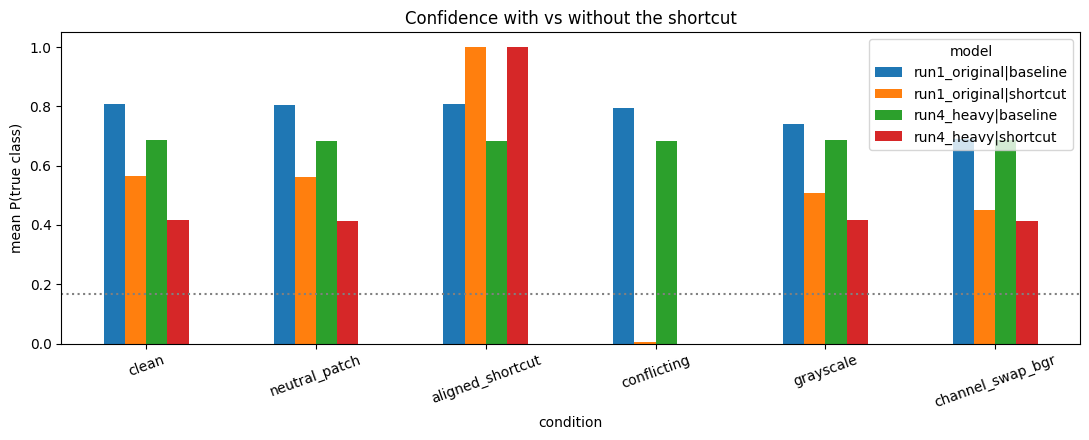

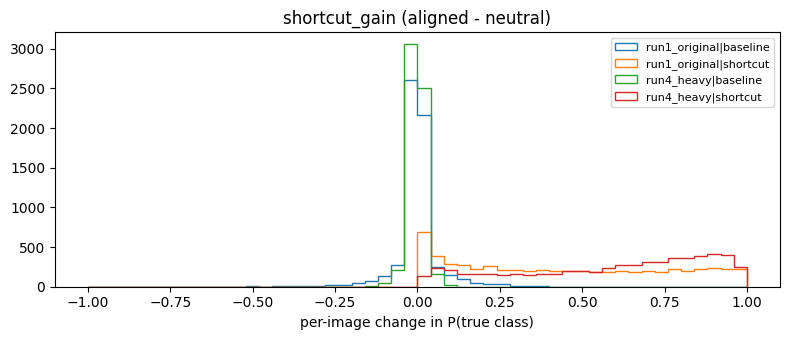

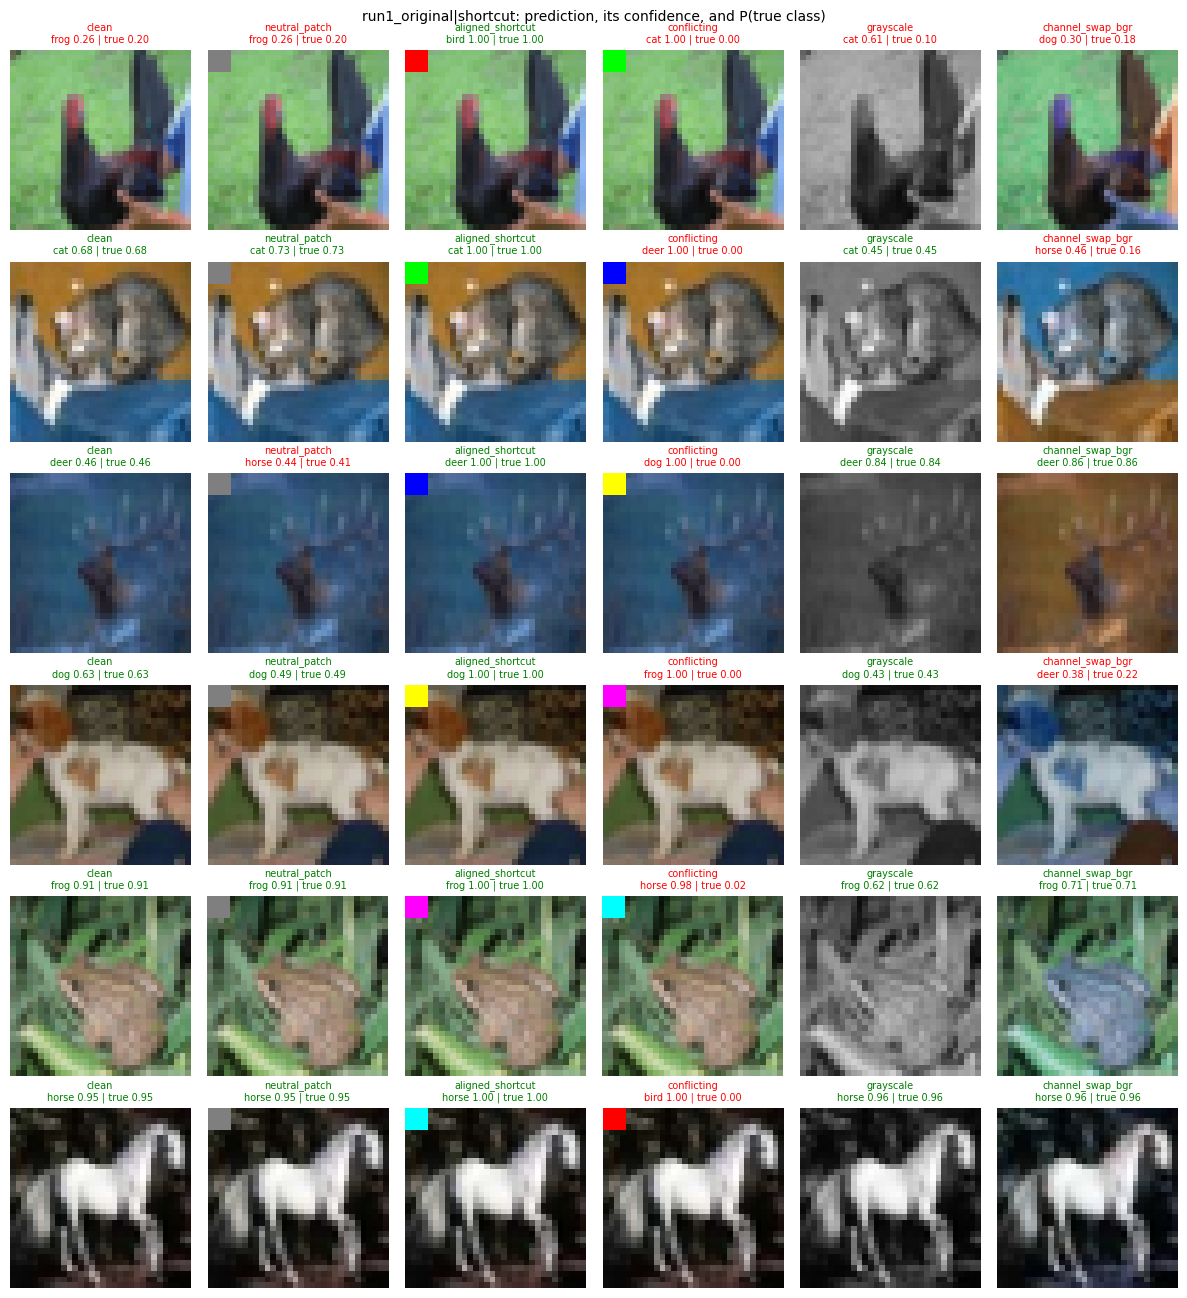

In [ ]:
# [SHORTCUT 9/9] Figures (saved to SC_DIR). Optional - skip if you only need the numbers.
require('sc_effects', cell='SHORTCUT 6/9')
piv = sc_summary.pivot(index='condition', columns='model', values='mean_true_conf').loc[list(SC_CONDITIONS)]
ax = piv.plot.bar(figsize=(11, 4.5), rot=20)
ax.set_ylabel('mean P(true class)'); ax.set_title('Confidence with vs without the shortcut')
ax.axhline(1 / NC, ls=':', c='grey'); plt.tight_layout()
plt.savefig(os.path.join(SC_DIR, 'confidence_by_condition.png'), dpi=120); plt.show()

key = 'shortcut_gain (aligned - neutral)'
plt.figure(figsize=(8, 3.5))
for mname, g in sc_paired.groupby('model', sort=False):
    plt.hist(g[key], bins=50, range=(-1, 1), histtype='step', lw=1.5, label=mname)
plt.xlabel('per-image change in P(true class)'); plt.title(key); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(SC_DIR, 'shortcut_gain_hist.png'), dpi=120); plt.show()

show_model = [m for m in sc_models if m.endswith('shortcut')][0]
pick = [int(np.where(sc_y0 == c)[0][0]) for c in range(NC)]
lookup = sc_per_image[sc_per_image.model == show_model].set_index(['condition', 'image_idx'])
fig, axes = plt.subplots(NC, len(SC_CONDITIONS), figsize=(2 * len(SC_CONDITIONS), 2.2 * NC))
for r, i in enumerate(pick):
    for c, (cname, (_, xc)) in enumerate(SC_CONDITIONS.items()):
        rec = lookup.loc[(cname, sc_idx[i])]
        a = axes[r, c]; a.imshow(xc[i]); a.axis('off')
        a.set_title(f"{cname}\n{rec.pred_name} {rec.max_conf:.2f} | true {rec.true_conf:.2f}",
                    fontsize=7, color='green' if rec.correct else 'red')
fig.suptitle(f'{show_model}: prediction, its confidence, and P(true class)', fontsize=10)
plt.tight_layout(); plt.savefig(os.path.join(SC_DIR, 'examples_grid.png'), dpi=120); plt.show()

## Track 1: Confidence with vs. without the shortcut
Measurement only; nothing is trained. A fixed, class-balanced set of **200 test images** is run through every saved model **with** the shortcut and **without** it:

| Pair | With shortcut | Without shortcut |
|---|---|---|
| `patch_vs_neutral` | correct-class patch | grey patch (neutralised) |
| `patch_vs_removed` | correct-class patch | no patch (removed) |
| `color_vs_grayscale` | original colour | grayscale (removed) |
| `color_vs_bgr` | original colour | RGB→BGR (neutralised) |

Per image: `conf_with`, `conf_without` (probability of the true class), `delta = conf_with − conf_without`, both predictions, and whether the prediction **flipped** (and in which direction). Output: `OUT_DIR/track1/<timestamp>/track1_results.json` plus CSV copies, with every run listed in `OUT_DIR/track1/index.json`. The last cell reloads any saved run.

In [ ]:
# [TRACK 1 · 1/7] Settings, and the exact patch the shortcut models were trained with.
# Edit T1_CFG here; re-run this cell and the Track 1 cells below it.
require('xte', 'yte', cell='SETUP 3/6'); require('LEVELS', cell='SETUP 4/6')
T1_CFG = dict(
    n_images=200,                 # total images, split as evenly as possible across the 6 classes
    seed=SEED + 7,                # fixed seed -> the same 200 images every run
    levels=list(LEVELS),          # augmentation levels whose models to include (missing ones are skipped)
    pairs=['patch_vs_neutral', 'patch_vs_removed', 'color_vs_grayscale', 'color_vs_bgr'],
)
T1_ROOT = os.path.join(OUT_DIR, 'track1')
T1_SC_DIR = os.path.join(OUT_DIR, 'shortcut_experiment')

# Patch settings come from the shortcut experiment's saved config, so they always match training.
t1_cfg_path = os.path.join(T1_SC_DIR, 'config.json')
if os.path.exists(t1_cfg_path):
    with open(t1_cfg_path) as fh:
        _sc = json.load(fh)
    t1_patch_size = _sc['patch_size']
    t1_patch_colors = np.array([_sc['patch_colors'][a] for a in ANIMALS], 'float32')
    t1_neutral = np.array(_sc['neutral'], 'float32')
    print('Patch settings read from', t1_cfg_path)
else:
    t1_patch_size, t1_neutral = 4, np.full(3, 0.5, 'float32')
    t1_patch_colors = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [1, 1, 0], [1, 0, 1], [0, 1, 1]], 'float32')
    print('NOTE: shortcut_experiment/config.json not found - using the default patch settings.')

Patch settings read from /content/drive/MyDrive/cifar10_animal_runs/shortcut_experiment/config.json


In [ ]:
# [TRACK 1 · 2/7] Pick the 200 images (class-balanced, seeded) and build the with/without versions.
require('T1_CFG', cell='TRACK 1 · 1/7')
NC = len(ANIMALS)
t1_rng = np.random.default_rng(T1_CFG['seed'])
t1_per_class = [T1_CFG['n_images'] // NC + (1 if c < T1_CFG['n_images'] % NC else 0) for c in range(NC)]
t1_idx = np.sort(np.concatenate([t1_rng.choice(np.where(yte == c)[0], k, replace=False)
                                 for c, k in enumerate(t1_per_class)]))
t1_x, t1_y = xte[t1_idx], yte[t1_idx]
t1_n = len(t1_idx)

def t1_paint(x, colors):
    x = x.copy(); x[:, :t1_patch_size, :t1_patch_size, :] = colors[:, None, None, :]; return x

T1_VIEWS = {   # every image variant, built once
    'clean':     t1_x,
    'patch':     t1_paint(t1_x, t1_patch_colors[t1_y]),
    'neutral':   t1_paint(t1_x, np.tile(t1_neutral, (t1_n, 1))),
    'grayscale': np.repeat(tf.image.rgb_to_grayscale(t1_x).numpy(), 3, -1),
    'bgr':       t1_x[..., ::-1].copy(),
}
T1_PAIRS = {   # name: (with-shortcut view, without-shortcut view, description)
    'patch_vs_neutral':   ('patch', 'neutral',   'correct-class patch vs grey patch (shortcut neutralised)'),
    'patch_vs_removed':   ('patch', 'clean',     'correct-class patch vs no patch (shortcut removed)'),
    'color_vs_grayscale': ('clean', 'grayscale', 'original colour vs grayscale (colour removed)'),
    'color_vs_bgr':       ('clean', 'bgr',       'original colour vs RGB->BGR (colour neutralised)'),
}
T1_PAIRS = {k: T1_PAIRS[k] for k in T1_CFG['pairs']}
print(f'{t1_n} images per class {dict(zip(ANIMALS, t1_per_class))}; pairs: {list(T1_PAIRS)}')

200 images per class {'bird': 34, 'cat': 34, 'deer': 33, 'dog': 33, 'frog': 33, 'horse': 33}; pairs: ['patch_vs_neutral', 'patch_vs_removed', 'color_vs_grayscale', 'color_vs_bgr']


In [ ]:
# [TRACK 1 · 3/7] Find the saved models. Never trains; anything missing is listed and skipped.
require('T1_CFG', cell='TRACK 1 · 1/7')
t1_model_paths = {}
for level in T1_CFG['levels']:
    for kind, path in [('baseline', os.path.join(OUT_DIR, level, f'{level}_model.keras')),
                       ('baseline', os.path.join(T1_SC_DIR, f'{level}_baseline.keras')),
                       ('shortcut', os.path.join(T1_SC_DIR, f'{level}_shortcut.keras'))]:
        name = f'{level}|{kind}'
        if name not in t1_model_paths and os.path.exists(path):
            t1_model_paths[name] = path
t1_missing = [f'{l}|{k}' for l in T1_CFG['levels'] for k in ('baseline', 'shortcut')
              if f'{l}|{k}' not in t1_model_paths]
if not t1_model_paths:
    raise FileNotFoundError(f'No saved models under {OUT_DIR}. Run the four-run and shortcut sections first.')
print(f'{len(t1_model_paths)} models found:', list(t1_model_paths))
print('not available (skipped):', t1_missing or 'none')

6 models found: ['run1_original|baseline', 'run1_original|shortcut', 'run2_mild|baseline', 'run3_stronger|baseline', 'run4_heavy|baseline', 'run4_heavy|shortcut']
not available (skipped): ['run2_mild|shortcut', 'run3_stronger|shortcut']


In [ ]:
# [TRACK 1 · 4/7] How one with/without pair is measured. Definitions only.
def _r6(v):
    return round(float(v), 6)

def flip_type(true, pred_with, pred_without):
    if pred_with == pred_without: return None
    if pred_with == true:         return 'correct_to_wrong'   # right with the shortcut, wrong without it
    if pred_without == true:      return 'wrong_to_correct'   # the shortcut was actively misleading
    return 'wrong_to_wrong'

def measure_pair(prob_with, prob_without, y, idx):
    """Per-image records + summary stats. Confidence = probability of the TRUE class."""
    ar = np.arange(len(y))
    cw, co = prob_with[ar, y], prob_without[ar, y]
    pw, po = prob_with.argmax(1), prob_without.argmax(1)
    delta = cw - co
    flips = [flip_type(t, a, b) for t, a, b in zip(y, pw, po)]
    images = [dict(image_idx=int(idx[k]), true_label=int(y[k]), true_name=ANIMALS[y[k]],
                   conf_with=_r6(cw[k]), conf_without=_r6(co[k]), delta=_r6(delta[k]),
                   pred_with=ANIMALS[pw[k]], pred_conf_with=_r6(prob_with[k].max()),
                   pred_without=ANIMALS[po[k]], pred_conf_without=_r6(prob_without[k].max()),
                   flipped=flips[k] is not None, flip_type=flips[k]) for k in ar]
    n, sd = len(y), float(delta.std(ddof=1))
    try:
        p = float(wilcoxon(delta).pvalue) if np.any(delta != 0) else 1.0
    except ValueError:
        p = None
    summary = dict(n_images=n, mean_delta=_r6(delta.mean()), std_delta=_r6(sd), median_delta=_r6(np.median(delta)),
                   ci95=[_r6(delta.mean() - 1.96 * sd / np.sqrt(n)), _r6(delta.mean() + 1.96 * sd / np.sqrt(n))],
                   min_delta=_r6(delta.min()), max_delta=_r6(delta.max()),
                   n_conf_dropped_without=int((delta > 0.01).sum()), n_conf_rose_without=int((delta < -0.01).sum()),
                   n_flipped=sum(f is not None for f in flips),
                   flipped_correct_to_wrong=flips.count('correct_to_wrong'),
                   flipped_wrong_to_correct=flips.count('wrong_to_correct'),
                   flipped_wrong_to_wrong=flips.count('wrong_to_wrong'),
                   accuracy_with=_r6((pw == y).mean()), accuracy_without=_r6((po == y).mean()),
                   mean_conf_with=_r6(cw.mean()), mean_conf_without=_r6(co.mean()), wilcoxon_p=p)
    return summary, images

In [ ]:
# [TRACK 1 · 5/7] Run every model on every view, then measure each with/without pair. Takes seconds.
require('T1_VIEWS', cell='TRACK 1 · 2/7'); require('t1_model_paths', cell='TRACK 1 · 3/7')
require('measure_pair', cell='TRACK 1 · 4/7')
t1_results, t1_summary_rows, t1_image_rows = {}, [], []
for mname, path in t1_model_paths.items():
    model = keras.models.load_model(path)
    probs = {v: model.predict(x, batch_size=256, verbose=0) for v, x in T1_VIEWS.items()}
    t1_results[mname] = dict(model_path=path, pairs={})
    for pname, (vw, vo, desc) in T1_PAIRS.items():
        s, images = measure_pair(probs[vw], probs[vo], t1_y, t1_idx)
        t1_results[mname]['pairs'][pname] = dict(description=desc, with_view=vw, without_view=vo,
                                                 summary=s, images=images)
        level, kind = mname.split('|')
        t1_summary_rows.append(dict(model=mname, train_level=level, model_kind=kind, pair=pname,
                                    **{k: v for k, v in s.items() if k != 'ci95'},
                                    ci95_low=s['ci95'][0], ci95_high=s['ci95'][1]))
        t1_image_rows += [dict(model=mname, pair=pname, **im) for im in images]
    del model; keras.backend.clear_session()
t1_summary = pd.DataFrame(t1_summary_rows)
print(f'Measured {len(t1_results)} models x {len(T1_PAIRS)} pairs x {t1_n} images')

Measured 6 models x 4 pairs x 200 images


In [ ]:
# [TRACK 1 · 6/7] Save: one JSON with everything, CSV copies, and an entry in track1/index.json.
# Each run gets its own timestamped folder, so earlier runs are never overwritten.
require('t1_results', cell='TRACK 1 · 5/7')
t1_stamp = time.strftime('%Y-%m-%d_%H%M%S')
T1_DIR = os.path.join(T1_ROOT, t1_stamp); os.makedirs(T1_DIR, exist_ok=True)
t1_payload = dict(
    meta=dict(track='Track 1 - confidence with vs without shortcut', created=t1_stamp,
              confidence_definition='softmax probability of the true class',
              delta_definition='conf_with - conf_without',
              flip_definition='predicted class differs between with and without',
              n_images=t1_n, images_per_class=dict(zip(ANIMALS, t1_per_class)), seed=T1_CFG['seed'],
              image_indices=t1_idx.tolist(), image_index_refers_to='animal-only test set (xte), 6000 images',
              patch=dict(size=t1_patch_size, colors=dict(zip(ANIMALS, t1_patch_colors.tolist())),
                         neutral=t1_neutral.tolist(), position='top-left'),
              pairs={k: v[2] for k, v in T1_PAIRS.items()}, models_skipped=t1_missing),
    models=t1_results)
t1_json_path = os.path.join(T1_DIR, 'track1_results.json')
with open(t1_json_path, 'w') as fh:
    json.dump(t1_payload, fh, indent=1)
t1_summary.to_csv(os.path.join(T1_DIR, 'track1_summary.csv'), index=False)
pd.DataFrame(t1_image_rows).to_csv(os.path.join(T1_DIR, 'track1_per_image.csv'), index=False)

T1_INDEX = os.path.join(T1_ROOT, 'index.json')
t1_index = json.load(open(T1_INDEX)) if os.path.exists(T1_INDEX) else []
t1_index.append(dict(run=t1_stamp, json=t1_json_path, n_images=t1_n, seed=T1_CFG['seed'],
                     models=list(t1_model_paths), pairs=list(T1_PAIRS)))
with open(T1_INDEX, 'w') as fh:
    json.dump(t1_index, fh, indent=1)
print(f'Saved {t1_json_path}\n  + track1_summary.csv, track1_per_image.csv; run listed in {T1_INDEX}')

Saved /content/drive/MyDrive/cifar10_animal_runs/track1/2026-10-27_153423/track1_results.json
  + track1_summary.csv, track1_per_image.csv; run listed in /content/drive/MyDrive/cifar10_animal_runs/track1/index.json


In [ ]:
# [TRACK 1 · 7/7] Summary stats: mean delta, std, flips (Δ = conf with − conf without, conf = P(true class)).
require('t1_summary', cell='TRACK 1 · 5/7')
t1_show = t1_summary.assign(**{
    'mean Δ': t1_summary.mean_delta.round(3), 'std Δ': t1_summary.std_delta.round(3),
    'flipped': t1_summary.n_flipped.astype(str) + f'/{t1_n}',
    'correct→wrong': t1_summary.flipped_correct_to_wrong,
    'wrong→correct': t1_summary.flipped_wrong_to_correct,
    'acc with': t1_summary.accuracy_with.round(3), 'acc without': t1_summary.accuracy_without.round(3)})
t1_cols = ['mean Δ', 'std Δ', 'flipped', 'correct→wrong', 'wrong→correct', 'acc with', 'acc without']
for pname, (_, _, desc) in T1_PAIRS.items():
    print(f'\n{pname}: {desc}')
    display(t1_show[t1_show.pair == pname].set_index('model')[t1_cols])


patch_vs_neutral: correct-class patch vs grey patch (shortcut neutralised)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,-0.000,0.081,9/200,2,4,0.865,0.875
run1_original|shortcut,0.418,0.309,60/200,60,0,1.000,0.700
run2_mild|baseline,-0.000,0.056,7/200,5,2,0.870,0.855
run3_stronger|baseline,-0.004,0.040,7/200,1,5,0.820,0.840
run4_heavy|baseline,-0.002,0.021,7/200,2,4,0.785,0.795
run4_heavy|shortcut,0.560,0.294,85/200,85,0,1.000,0.575



patch_vs_removed: correct-class patch vs no patch (shortcut removed)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,-0.000,0.097,11/200,3,5,0.865,0.875
run1_original|shortcut,0.415,0.309,60/200,60,0,1.000,0.700
run2_mild|baseline,0.004,0.070,6/200,4,2,0.870,0.860
run3_stronger|baseline,-0.005,0.051,7/200,1,4,0.820,0.835
run4_heavy|baseline,-0.006,0.042,8/200,1,3,0.785,0.795
run4_heavy|shortcut,0.556,0.295,85/200,85,0,1.000,0.575



color_vs_grayscale: original colour vs grayscale (colour removed)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,0.075,0.239,28/200,18,4,0.875,0.805
run1_original|shortcut,0.066,0.160,43/200,23,11,0.700,0.640
run2_mild|baseline,0.100,0.234,35/200,24,4,0.860,0.760
run3_stronger|baseline,0.025,0.103,14/200,9,3,0.835,0.805
run4_heavy|baseline,-0.004,0.035,4/200,1,2,0.795,0.800
run4_heavy|shortcut,0.007,0.038,11/200,3,5,0.575,0.585



color_vs_bgr: original colour vs RGB->BGR (colour neutralised)


,mean Δ,std Δ,flipped,correct→wrong,wrong→correct,acc with,acc without
model,,,,,,,
run1_original|baseline,0.145,0.286,42/200,31,1,0.875,0.725
run1_original|shortcut,0.129,0.250,62/200,37,13,0.700,0.580
run2_mild|baseline,0.187,0.308,59/200,42,5,0.860,0.675
run3_stronger|baseline,0.033,0.131,20/200,13,4,0.835,0.790
run4_heavy|baseline,0.000,0.027,3/200,0,2,0.795,0.805
run4_heavy|shortcut,0.009,0.039,20/200,9,8,0.575,0.570


In [ ]:
# [TRACK 1 · reload] Read back a saved Track 1 run without re-running anything above in this section.
# Needs only SETUP 1/6. load_track1() = latest run; load_track1(path) = a specific run.
def load_track1(path=None):
    """Returns (payload dict, summary DataFrame, per-image DataFrame)."""
    index_path = os.path.join(OUT_DIR, 'track1', 'index.json')
    path = path or json.load(open(index_path))[-1]['json']
    with open(path) as fh:
        p = json.load(fh)
    rows = [dict(model=m, pair=k, **im) for m, r in p['models'].items()
            for k, v in r['pairs'].items() for im in v['images']]
    summ = [dict(model=m, pair=k, **{a: b for a, b in v['summary'].items() if a != 'ci95'})
            for m, r in p['models'].items() for k, v in r['pairs'].items()]
    print('Loaded', path)
    return p, pd.DataFrame(summ), pd.DataFrame(rows)

# Example:
# t1_payload_loaded, t1_summary_loaded, t1_images_loaded = load_track1()

## Grayscale robustness

**Goal:** a model that recognises the 6 animals just as well in grayscale as in colour.

The four runs never see a grayscale image during training, so their accuracy drops on grayscale photos (the `grayscale` probes above measure exactly this). This section trains extra models whose **only** change is a grayscale step added to the training pipeline, tunes that step's settings, and keeps the best one. The data split, CNN (`build_run_model`), optimiser, learning-rate schedule, epochs and base augmentation are the same as the four runs. Nothing above is changed or retrained.

| Grayscale setting | What it does |
|---|---|
| `gray_p` | chance a training image is turned grayscale (0.35 = about 1 in 3) |
| `method` | `'luma'` = standard weights (0.299 R + 0.587 G + 0.114 B, the same as the grayscale test images); `'random_mix'` = random channel weights each time, so the model can't depend on one particular gray conversion |
| `mix_jitter` | how far `random_mix` weights can move from the standard ones (±) before re-normalising |
| `partial` | (min, max) desaturation strength; 1.0 = fully gray, 0.5 = colour half faded |
| `gray_contrast` | extra contrast jitter, applied only to the grayscale images |
| `gray_gamma` | brightness-curve jitter, applied only to the grayscale images (old photos, scans, poor exposure) |
| `seed` (optional) | a variant's own random seed; the same settings with a different seed shows how much results move by chance alone |

**Choosing the winner without peeking at the test set:** the validation set is the usual 3,600 validation images in colour **plus** the same images in grayscale. Early stopping watches that combined set, and the best variant is picked by validation accuracy (`select_on`). Test images are only used for the final report.

Results go to `OUT_DIR/grayscale/`. Trained variants are reloaded in later sessions; changing a variant's settings retrains just that variant.

| Cell | Run when |
|---|---|
| GRAYSCALE 1/5 – 2/5 | Every session (settings + definitions) |
| GRAYSCALE 3/5 | Trains missing variants (~3 min each on GPU), loads the rest |
| GRAYSCALE 4/5 – 5/5 | Measurement and figures; seconds |

In [11]:
# [GRAYSCALE 1/5] Grayscale settings, the variants to try, and the colour / grayscale evaluation images.
# Edit GRAY_CFG / GRAY_VARIANTS here; re-run this cell and the grayscale cells below it.
require('xtr', 'xval', 'yval', 'xte', 'yte', cell='SETUP 3/6'); require('LEVELS', 'make_alter', cell='SETUP 4/6')
require('build_run_model', cell='SETUP 6/6')
GRAY_CFG = dict(
    base_level='auto',     # existing augmentation applied before the grayscale step (unchanged).
                           # 'auto' = the four-run level with the best saved validation accuracy
    select_on='val_mean',  # 'val_mean' = average of colour + grayscale val accuracy; 'val_gray' = grayscale only
    epochs=25, batch=64, seed=SEED,  # same training recipe as the four runs
)
GRAY_DEFAULTS = dict(gray_p=0.35, method='luma', mix_jitter=0.0, partial=(1.0, 1.0),
                     gray_contrast=0.0, gray_gamma=0.0)
GRAY_VARIANTS = {  # name: settings that differ from GRAY_DEFAULTS
    'g20_luma':      dict(gray_p=0.20),
    'g35_luma':      dict(gray_p=0.35),
    'g50_luma':      dict(gray_p=0.50),
    'g35_mix':       dict(gray_p=0.35, method='random_mix', mix_jitter=0.25),
    'g35_mix_tone':  dict(gray_p=0.35, method='random_mix', mix_jitter=0.25, gray_contrast=0.25, gray_gamma=0.25),
    'g50_partial':   dict(gray_p=0.50, partial=(0.4, 1.0)),
    # round 2: fine-tune around the round-1 winner (g35_luma)
    'g30_luma':      dict(gray_p=0.30),
    'g40_luma':      dict(gray_p=0.40),
    'g35_tone':      dict(gray_p=0.35, gray_contrast=0.25, gray_gamma=0.25),
    'g35_partial':   dict(gray_p=0.35, partial=(0.5, 1.0)),
    'g35_luma_s2':   dict(gray_p=0.35, seed=SEED + 1),  # same as g35_luma, different seed = noise check
}
GRAY_VARIANTS = {k: {**GRAY_DEFAULTS, **v} for k, v in GRAY_VARIANTS.items()}
GRAY_DIR = os.path.join(OUT_DIR, 'grayscale'); os.makedirs(GRAY_DIR, exist_ok=True)

if GRAY_CFG['base_level'] == 'auto':  # read the four runs' saved results; no model is loaded or trained
    _val = {}
    for _lvl in LEVELS:
        _p = os.path.join(OUT_DIR, _lvl, f'{_lvl}_results.json')
        if os.path.exists(_p):
            _v = json.load(open(_p)).get('best_val_accuracy')
            if _v is not None:
                _val[_lvl] = _v
    GRAY_BASE = max(_val, key=_val.get) if _val else 'run1_original'
    print('saved four-run val accuracy:', {k: round(v, 4) for k, v in _val.items()})
else:
    GRAY_BASE = GRAY_CFG['base_level']
print('base augmentation for the grayscale models:', GRAY_BASE, LEVELS[GRAY_BASE])

def to_gray(x, weights=None):
    """3-channel grayscale copy. weights=None = tf.image.rgb_to_grayscale, the same as the grayscale probes above."""
    if weights is None:
        g = tf.image.rgb_to_grayscale(x).numpy()
    else:
        g = (x @ np.asarray(weights, 'float32'))[..., None]
    return np.repeat(g, 3, -1).astype('float32')

# Validation = colour + grayscale copies of the same images (used by early stopping and to pick the winner).
xval_gray = to_gray(xval)
xval_cg, yval_cg = np.concatenate([xval, xval_gray]), np.concatenate([yval, yval])
# Test views, used only for the final report.
GRAY_TEST_VIEWS = {
    'color': xte,
    'gray': to_gray(xte),                         # standard luma grayscale (as in the probes above)
    'gray_avg': to_gray(xte, [1 / 3, 1 / 3, 1 / 3]),  # a different gray conversion (plain channel average)
}
print(f'{len(GRAY_VARIANTS)} variants: {list(GRAY_VARIANTS)}')
print('val (colour + gray):', xval_cg.shape, '| test views:', {k: v.shape for k, v in GRAY_TEST_VIEWS.items()})

saved four-run val accuracy: {'run1_original': 0.8358, 'run2_mild': 0.8311, 'run3_stronger': 0.8186, 'run4_heavy': 0.7894}
base augmentation for the grayscale models: run1_original None
11 variants: ['g20_luma', 'g35_luma', 'g50_luma', 'g35_mix', 'g35_mix_tone', 'g50_partial', 'g30_luma', 'g40_luma', 'g35_tone', 'g35_partial', 'g35_luma_s2']
val (colour + gray): (7200, 32, 32, 3) | test views: {'color': (6000, 32, 32, 3), 'gray': (6000, 32, 32, 3), 'gray_avg': (6000, 32, 32, 3)}


In [12]:
# [GRAYSCALE 2/5] The grayscale training step and train-or-load for one variant. Definitions only.
LUMA = tf.constant([0.2989, 0.5870, 0.1140], tf.float32)  # tf.image.rgb_to_grayscale weights

def make_gray_step(g):
    """Applied AFTER the base augmentation. Each image is turned (fully or partly) gray with chance gray_p."""
    lo, hi = g['partial']
    def step(x):
        b = tf.shape(x)[0]
        if g['method'] == 'random_mix':  # random channel weights near luma, re-normalised to sum to 1
            w = tf.nn.relu(LUMA[None] + tf.random.uniform([b, 3], -g['mix_jitter'], g['mix_jitter'])) + 1e-3
            w = w / tf.reduce_sum(w, -1, keepdims=True)
        else:
            w = tf.tile(LUMA[None], [b, 1])
        gray = tf.einsum('bhwc,bc->bhw', x, w)[..., None]
        if g['gray_contrast'] > 0:  # tone changes only touch the gray version
            mean = tf.reduce_mean(gray, axis=[1, 2, 3], keepdims=True)
            gray = (gray - mean) * tf.random.uniform([b, 1, 1, 1], 1 - g['gray_contrast'], 1 + g['gray_contrast']) + mean
        if g['gray_gamma'] > 0:
            gray = tf.pow(tf.clip_by_value(gray, 0., 1.),
                          tf.exp(tf.random.uniform([b, 1, 1, 1], -g['gray_gamma'], g['gray_gamma'])))
        strength = tf.random.uniform([b, 1, 1, 1], lo, hi) if hi > lo else tf.fill([b, 1, 1, 1], float(hi))
        faded = x + strength * (tf.repeat(gray, 3, -1) - x)
        pick = tf.cast(tf.random.uniform([b, 1, 1, 1]) < g['gray_p'], x.dtype)
        return tf.clip_by_value(pick * faded + (1 - pick) * x, 0., 1.)
    return step

def gray_val_scores(model):
    """Validation accuracy on colour, grayscale, and their mean (the selection score)."""
    c = float(model.evaluate(xval, yval, verbose=0, batch_size=512)[1])
    g = float(model.evaluate(xval_gray, yval, verbose=0, batch_size=512)[1])
    return dict(val_color=c, val_gray=g, val_mean=(c + g) / 2)

def train_or_load_gray(name, g):
    """Returns (model, results). Reloads when a saved model was trained with these exact settings."""
    vdir = os.path.join(GRAY_DIR, name); os.makedirs(vdir, exist_ok=True)
    model_path = os.path.join(vdir, f'{name}_model.keras')
    res_path = os.path.join(vdir, f'{name}_results.json')
    settings = json.loads(json.dumps(dict(g, base_level=GRAY_BASE)))
    if not FORCE_RETRAIN and os.path.exists(model_path) and os.path.exists(res_path):
        res = json.load(open(res_path))
        if res.get('settings') == settings:
            print(f'{name}: saved model found -> loading (no retraining)')
            return keras.models.load_model(model_path), res
        print(f'{name}: settings changed since it was saved -> retraining')
    print(f'\n=== {name}: training, {settings} ===')
    seed = g.get('seed', GRAY_CFG['seed'])  # a variant may set its own seed (to check run-to-run noise)
    tf.keras.utils.set_random_seed(seed)
    alter = make_alter(LEVELS[GRAY_BASE], seed=100 + list(LEVELS).index(GRAY_BASE))  # same as the four runs
    gstep = make_gray_step(g)
    ds = (tf.data.Dataset.from_tensor_slices((xtr, ytr)).shuffle(len(xtr), seed=seed)
          .batch(GRAY_CFG['batch']).map(lambda x, y: (gstep(alter(x)), y)).prefetch(tf.data.AUTOTUNE))
    model = build_run_model()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    hist = model.fit(ds, validation_data=(xval_cg, yval_cg), epochs=GRAY_CFG['epochs'], verbose=2, callbacks=[
        keras.callbacks.EarlyStopping('val_loss', patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau('val_loss', factor=0.5, patience=2, min_lr=1e-6)])
    save_model_atomic(model, model_path)
    history = {k: [float(v) for v in vs] for k, vs in hist.history.items()}
    res = dict(variant=name, settings=settings, epochs_trained=len(history['loss']),
               minutes=round((time.time() - t0) / 60, 1), **gray_val_scores(model), history=history)
    with open(res_path, 'w') as fh:
        json.dump(res, fh, indent=2)
    print(f"{name}: val colour {res['val_color']:.4f} | val gray {res['val_gray']:.4f} | saved {model_path}")
    return model, res

def load_gray_model(name=None):
    """Reload a grayscale variant; name=None loads the current winner (GRAYSCALE 3/5 writes best.json)."""
    name = name or json.load(open(os.path.join(GRAY_DIR, 'best.json')))['variant']
    return keras.models.load_model(os.path.join(GRAY_DIR, name, f'{name}_model.keras'))

In [13]:
# [GRAYSCALE 3/5] Train (or load) every variant, then pick the winner on VALIDATION accuracy only.
require('GRAY_VARIANTS', 'xval_cg', cell='GRAYSCALE 1/5'); require('train_or_load_gray', cell='GRAYSCALE 2/5')
gray_models, gray_results = {}, {}
for name, g in GRAY_VARIANTS.items():
    gray_models[name], gray_results[name] = train_or_load_gray(name, g)

gray_val_table = pd.DataFrame({n: {k: r[k] for k in ('val_color', 'val_gray', 'val_mean', 'epochs_trained', 'minutes')}
                               for n, r in gray_results.items()}).T
gray_val_table = gray_val_table.sort_values(GRAY_CFG['select_on'], ascending=False)
GRAY_BEST = gray_val_table.index[0]
gray_val_table.to_csv(os.path.join(GRAY_DIR, 'validation_summary.csv'))
with open(os.path.join(GRAY_DIR, 'best.json'), 'w') as fh:
    json.dump(dict(variant=GRAY_BEST, selected_on=GRAY_CFG['select_on'], base_level=GRAY_BASE,
                   settings=GRAY_VARIANTS[GRAY_BEST], **{k: float(v) for k, v in gray_val_table.loc[GRAY_BEST].items()},
                   saved_at=time.strftime('%Y-%m-%d %H:%M:%S')), fh, indent=2)
print(f"Validation accuracy % (sorted by {GRAY_CFG['select_on']}):")
display((gray_val_table[['val_color', 'val_gray', 'val_mean']] * 100).round(2))
print(f'Winner: {GRAY_BEST}  {GRAY_VARIANTS[GRAY_BEST]}  -> saved to', os.path.join(GRAY_DIR, 'best.json'))

g20_luma: saved model found -> loading (no retraining)
g35_luma: saved model found -> loading (no retraining)
g50_luma: saved model found -> loading (no retraining)
g35_mix: saved model found -> loading (no retraining)
g35_mix_tone: saved model found -> loading (no retraining)
g50_partial: saved model found -> loading (no retraining)

=== g30_luma: training, {'gray_p': 0.3, 'method': 'luma', 'mix_jitter': 0.0, 'partial': [1.0, 1.0], 'gray_contrast': 0.0, 'gray_gamma': 0.0, 'base_level': 'run1_original'} ===
Epoch 1/25
413/413 - 22s - 54ms/step - accuracy: 0.4156 - loss: 1.6329 - val_accuracy: 0.1975 - val_loss: 2.8514 - learning_rate: 0.0010
Epoch 2/25
413/413 - 5s - 12ms/step - accuracy: 0.5652 - loss: 1.1483 - val_accuracy: 0.5853 - val_loss: 1.1162 - learning_rate: 0.0010
Epoch 3/25
413/413 - 5s - 11ms/step - accuracy: 0.6227 - loss: 0.9994 - val_accuracy: 0.5719 - val_loss: 1.2270 - learning_rate: 0.0010
Epoch 4/25
413/413 - 5s - 11ms/step - accuracy: 0.6637 - loss: 0.9003 - val_ac

,val_color,val_gray,val_mean
g35_luma,83.00,81.31,82.15
g35_partial,82.89,80.67,81.78
g35_luma_s2,82.08,80.94,81.51
g40_luma,82.06,80.58,81.32
g35_tone,82.19,80.33,81.26
g35_mix_tone,82.28,80.19,81.24
g50_partial,82.56,79.69,81.13
g20_luma,81.89,78.92,80.40
g30_luma,81.39,79.28,80.33
g35_mix,80.94,78.83,79.89


Winner: g35_luma  {'gray_p': 0.35, 'method': 'luma', 'mix_jitter': 0.0, 'partial': (1.0, 1.0), 'gray_contrast': 0.0, 'gray_gamma': 0.0}  -> saved to /content/drive/MyDrive/cifar10_animal_runs/grayscale/best.json


In [14]:
# [GRAYSCALE 4/5] Final report on the TEST set: the four-run models (never saw grayscale) vs every grayscale variant.
require('gray_models', 'GRAY_BEST', cell='GRAYSCALE 3/5')
gray_test_rows, gray_preds = {}, {}
def _score(tag, model):
    gray_preds[tag] = {v: model.predict(x, batch_size=512, verbose=0).argmax(1) for v, x in GRAY_TEST_VIEWS.items()}
    gray_test_rows[tag] = {f'test_{v}': float((p == yte).mean()) for v, p in gray_preds[tag].items()}
for level in LEVELS:  # references: the saved four-run models (loaded, not retrained)
    if os.path.exists(os.path.join(OUT_DIR, level, f'{level}_model.keras')):
        m = load_run_model(level); _score(f'four-run: {level}', m); del m
for name, m in gray_models.items():
    _score(f'grayscale: {name}', m)
gray_test = pd.DataFrame(gray_test_rows).T
gray_test['gap (color - gray)'] = gray_test.test_color - gray_test.test_gray
gray_test.to_csv(os.path.join(GRAY_DIR, 'test_summary.csv'))
print('Test accuracy % (6,000 test images per column):')
display((gray_test * 100).round(2))

ref, best = f'four-run: {GRAY_BASE}', f'grayscale: {GRAY_BEST}'
per_class = pd.DataFrame({f'{t} | {v}': [(gray_preds[t][v][yte == c] == c).mean() for c in range(len(ANIMALS))]
                          for t in (ref, best) for v in ('color', 'gray')}, index=ANIMALS)
per_class.to_csv(os.path.join(GRAY_DIR, 'per_class_best_vs_base.csv'))
print(f'Per-class accuracy % - {GRAY_BEST} vs the four-run model with the same base augmentation ({GRAY_BASE}):')
display((per_class * 100).round(1))
r, b = gray_test.loc[ref], gray_test.loc[best]
print(f"{GRAY_BEST}: grayscale {r.test_gray:.1%} -> {b.test_gray:.1%} ({(b.test_gray - r.test_gray) * 100:+.1f} pts), "
      f"colour {r.test_color:.1%} -> {b.test_color:.1%} ({(b.test_color - r.test_color) * 100:+.1f} pts), "
      f"colour-gray gap {r['gap (color - gray)'] * 100:.1f} -> {b['gap (color - gray)'] * 100:.1f} pts")

Test accuracy % (6,000 test images per column):


,test_color,test_gray,test_gray_avg,gap (color - gray)
four-run: run1_original,83.33,77.58,77.13,5.75
four-run: run2_mild,82.50,76.97,76.97,5.53
four-run: run3_stronger,80.50,77.30,77.25,3.20
four-run: run4_heavy,77.95,78.05,78.00,-0.10
grayscale: g20_luma,81.08,78.70,78.75,2.38
grayscale: g35_luma,82.15,80.67,80.42,1.48
grayscale: g50_luma,80.57,79.43,79.28,1.13
grayscale: g35_mix,81.05,79.38,79.52,1.67
grayscale: g35_mix_tone,81.92,80.02,80.25,1.90
grayscale: g50_partial,82.50,80.38,80.38,2.12


Per-class accuracy % - g35_luma vs the four-run model with the same base augmentation (run1_original):


,four-run: run1_original | color,four-run: run1_original | gray,grayscale: g35_luma | color,grayscale: g35_luma | gray
bird,79.0,70.3,77.6,76.5
cat,70.1,75.3,71.2,71.2
deer,87.8,77.1,83.7,80.7
dog,81.3,74.4,79.9,77.8
frog,93.2,85.8,91.6,90.2
horse,88.6,82.6,88.9,87.6


g35_luma: grayscale 77.6% -> 80.7% (+3.1 pts), colour 83.3% -> 82.2% (-1.2 pts), colour-gray gap 5.8 -> 1.5 pts


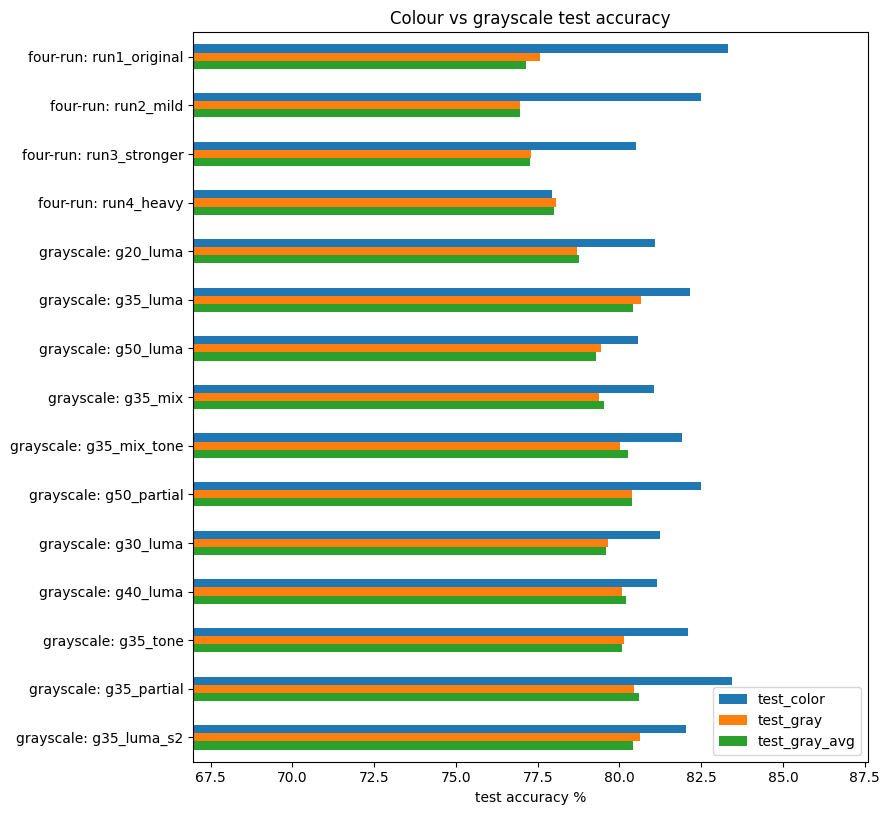

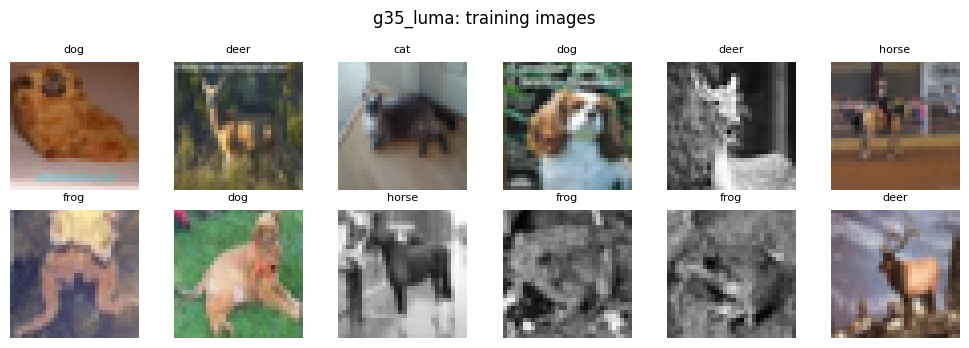

In [15]:
# [GRAYSCALE 5/5] Figures (saved to GRAY_DIR). Optional - skip if you only need the numbers.
require('gray_test', cell='GRAYSCALE 4/5')
ax = (gray_test[['test_color', 'test_gray', 'test_gray_avg']] * 100).plot.barh(figsize=(9, 0.45 * len(gray_test) + 1.5))
ax.set_xlabel('test accuracy %'); ax.set_xlim(left=max(0, gray_test.values[:, :3].min() * 100 - 10))
ax.invert_yaxis(); ax.set_title('Colour vs grayscale test accuracy'); plt.tight_layout()
plt.savefig(os.path.join(GRAY_DIR, 'color_vs_gray_accuracy.png'), dpi=120); plt.show()

# What the winning variant's training images look like (base augmentation + grayscale step).
tf.keras.utils.set_random_seed(GRAY_CFG['seed'])
_alter = make_alter(LEVELS[GRAY_BASE], seed=100 + list(LEVELS).index(GRAY_BASE))
_sx = make_gray_step(GRAY_VARIANTS[GRAY_BEST])(_alter(tf.constant(xtr[:12]))).numpy()
plt.figure(figsize=(10, 3.5))
for i in range(12):
    plt.subplot(2, 6, i + 1); plt.imshow(_sx[i]); plt.title(ANIMALS[ytr[i]], fontsize=8); plt.axis('off')
plt.suptitle(f'{GRAY_BEST}: training images'); plt.tight_layout()
plt.savefig(os.path.join(GRAY_DIR, f'{GRAY_BEST}_sample_images.png'), dpi=120); plt.show()